# ACROBAT: Q-Learning y Dyna-Q

Este notebook carga los **modelos entregados** y los **resultados registrados** en `results/`, y muestra las figuras del informe. **No vuelve a entrenar**: entrenar lleva minutos y se hace con los scripts (sección 6). Cada decisión técnica está explicada en `../docs/DECISIONES.md`, y se cita como D-XX.

Las restricciones que pidió el docente se cumplen: la recompensa es la original del entorno (−1 por paso), sin *reward shaping*, y la tabla Q arranca en **Q₀ = −100 = −1/(1−γ)**, que es estrictamente no optimista (D-17).

Para ver al agente en una ventana de pygame, poner `RENDER = True` en la celda siguiente.

In [1]:
import io
import json
import pickle

import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, Markdown, display

import plots  # figuras del informe: leen results/ y guardan en figures/
from evaluate_model import RandomAgent
from experiment_log import RESULTS_DIR
from qlearning import load_model
from train import TEST_SEED_BASE, evaluate, make_env, run_episode

RENDER = False  # True: muestra episodios en una ventana de pygame

# Modelos entregados (D-38).
MODELS = {"Q-Learning": plots.latest_model(plots.MODEL_QL), "Dyna-Q": plots.latest_model(plots.MODEL_DYNAQ)}
for name, stem in MODELS.items():
    print(f"{name:<11} models/{stem}.pkl")

Q-Learning  models/qlearning_final_rango10k_20261123-211904_5a2f.pkl
Dyna-Q      models/dynaq_final_rango_20261123-211208_4a66.pkl


## 1. El entorno

| | |
|---|---|
| Observación | `[cos θ1, sin θ1, cos θ2, sin θ2, ω1, ω2]`, con ω1 ∈ [−4π, 4π] y ω2 ∈ [−9π, 9π] |
| Acciones | 3: torque −1, 0 y +1 en la articulación del medio |
| Recompensa | −1 por paso hasta llegar a la meta (la punta por encima de la línea) |
| Fin del episodio | al llegar a la meta, o por corte a los 700 pasos |

**Discretización** (D-06, D-18 y D-38): los cos/sin se convierten en ángulos con `atan2`, lo que deja 4 dimensiones en vez de 6. Después se usan bins de igual ancho: (6, 6, 10, 10) para (θ1, θ2, ω1, ω2), con ω1 ∈ ±5 y ω2 ∈ ±10. Las velocidades fuera de ese rango caen en el bin extremo. La tabla tiene 3600 celdas × 3 acciones.

In [2]:
env = gym.make("Acrobot-v1", max_episode_steps=700)
print("Observaciones:", env.observation_space)
print("Acciones:     ", env.action_space)
env.close()

Observaciones: Box([ -1.        -1.        -1.        -1.       -12.566371 -28.274334], [ 1.        1.        1.        1.       12.566371 28.274334], (6,), float32)
Acciones:      Discrete(3)


## 2. Modelos entregados

Cada `.pkl` guarda la tabla Q, el discretizador (sin él, la tabla no sirve), los hiperparámetros y la configuración completa de la corrida (D-10).

In [3]:
rows = ["| | Q-Learning | Dyna-Q |", "|---|---|---|"]
info = {}
for name, stem in MODELS.items():
    with open(f"models/{stem}.pkl", "rb") as f:
        data = pickle.load(f)
    c, a, d = data["config"], data["config"]["agent"], data["config"]["discretization"]
    visited = (data["Q"] != a["q_init"]).any(axis=1).mean()
    info[name] = {
        "Episodios de entrenamiento": c["episodes"],
        "Q₀": a["q_init"],
        "α": a["alpha"],
        "γ": a["gamma"],
        "ε": f"{a['epsilon_start']} → {a['epsilon_min']} (decay {a['epsilon_decay']})",
        "Pasos de planning n": a.get("n_planning", "—"),
        "Bins (θ1, θ2, ω1, ω2)": tuple(d["bins"]),
        "Rango de ω1 / ω2": f"±{d['omega1_max']} / ±{d['omega2_max']}",
        "Celdas de la tabla": data["Q"].shape[0],
        "Celdas visitadas": f"{visited:.0%}",
    }
for key in info["Q-Learning"]:
    rows.append(f"| {key} | {info['Q-Learning'][key]} | {info['Dyna-Q'][key]} |")
display(Markdown("\n".join(rows)))

| | Q-Learning | Dyna-Q |
|---|---|---|
| Episodios de entrenamiento | 10000 | 10000 |
| Q₀ | -100.0 | -100.0 |
| α | 0.5 | 0.05 |
| γ | 0.99 | 0.99 |
| ε | 1.0 → 0.01 (decay 0.999) | 1.0 → 0.01 (decay 0.999) |
| Pasos de planning n | — | 2 |
| Bins (θ1, θ2, ω1, ω2) | (6, 6, 10, 10) | (6, 6, 10, 10) |
| Rango de ω1 / ω2 | ±5.0 / ±10.0 | ±5.0 / ±10.0 |
| Celdas de la tabla | 3600 | 3600 |
| Celdas visitadas | 54% | 61% |

## 3. Evaluación sobre los estados de prueba

Los modelos se evaluaron con la política greedy (ε = 0) sobre **1000 estados iniciales de prueba** (semillas desde 2 000 000), que no se usaron para elegir nada (D-09, D-35). El agente al azar se evaluó sobre los mismos estados.

La celda vuelve a jugar los primeros 100 estados con cada modelo y comprueba que los pasos coinciden uno por uno con los registrados. Así se verifica que el `.pkl` es el mismo modelo que se evaluó.

In [4]:
N_CHECK = 100
rows = ["| Agente | Pasos medios (1000) | Mín. | Máx. | Éxito | Verificación (100 estados) |", "|---|---|---|---|---|---|"]
agents = {name: load_model(f"models/{stem}.pkl") for name, stem in MODELS.items()}
agents["Al azar"] = (RandomAgent(seed=0), agents["Q-Learning"][1])
stems = dict(MODELS, **{"Al azar": "random"})
env = make_env(700)
for name, (agent, discretizer) in agents.items():
    with open(RESULTS_DIR / f"{stems[name]}_test.json", encoding="utf-8") as f:
        test = json.load(f)
    now = evaluate(env, agent, discretizer, N_CHECK, seed_base=TEST_SEED_BASE, per_episode=True)
    same = now["steps_per_episode"] == test["steps_per_episode"][:N_CHECK]
    rows.append(f"| {name} | {test['mean_steps']:.1f} | {test['min_steps']} | {test['max_steps']} | "
                f"{test['success_rate']:.1%} | {'coincide' if same else 'NO coincide'} |")
env.close()
display(Markdown("\n".join(rows)))

| Agente | Pasos medios (1000) | Mín. | Máx. | Éxito | Verificación (100 estados) |
|---|---|---|---|---|---|
| Q-Learning | 172.0 | 86 | 700 | 99.9% | coincide |
| Dyna-Q | 140.6 | 86 | 700 | 99.9% | coincide |
| Al azar | 693.2 | 320 | 700 | 5.8% | coincide |

## 4. Un episodio de Dyna-Q

Fotos de un episodio greedy de Dyna-Q desde el primer estado de prueba. El agente balancea el péndulo para ganar energía y después levanta la punta por encima de la línea.

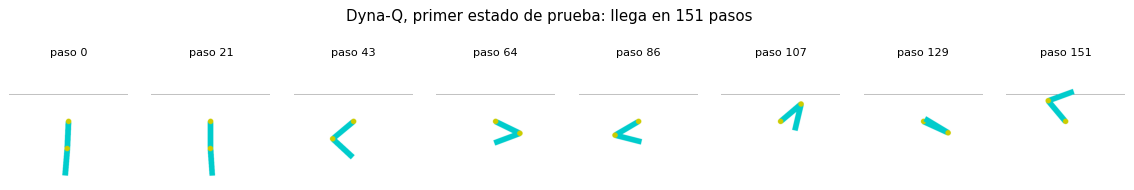

In [5]:
agent, discretizer = agents["Dyna-Q"]
env = gym.make("Acrobot-v1", render_mode="rgb_array", max_episode_steps=700)
obs, _ = env.reset(seed=TEST_SEED_BASE)
frames, done, steps = [env.render()], False, 0
while not done:
    obs, _, terminated, truncated, _ = env.step(agent.act(discretizer(obs), greedy=True))
    frames.append(env.render())
    steps += 1
    done = terminated or truncated
env.close()

picks = np.linspace(0, len(frames) - 1, 8).astype(int)
fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
for ax, i in zip(axes, picks):
    ax.imshow(frames[i])
    ax.set_title(f"paso {i}", fontsize=9)
    ax.axis("off")
fig.suptitle(f"Dyna-Q, primer estado de prueba: {'llega' if terminated else 'no llega'} en {steps} pasos")
buf = io.BytesIO()
fig.savefig(buf, format="png", dpi=90, bbox_inches="tight")
plt.close(fig)
display(Image(data=buf.getvalue()))

if RENDER:  # el mismo agente en una ventana de pygame, sobre 3 estados de prueba
    env = gym.make("Acrobot-v1", render_mode="human", max_episode_steps=700)
    for i in range(3):
        _, steps, success, _ = run_episode(env, agent, discretizer, learn=False, seed=TEST_SEED_BASE + i)
        print(f"estado de prueba {i}: {steps} pasos, {'llegó' if success else 'no llegó'}")
    env.close()

## 5. Figuras

`plots.py` genera todas las figuras desde los registros de `results/`: los JSON por corrida, los CSV por episodio y las evaluaciones de prueba (D-37). Nunca grafica desde variables en memoria. La celda siguiente las regenera; tarda unos 20 segundos.

In [6]:
for name, make_figure in plots.FIGURES.items():
    print(name)
    make_figure()

A1
  figures\A1_curva_modelo_final.png
A2
  figures\A2_pes_alpha.png
  figures\A2_pes_bins.png
  figures\A2_pes_epsilon.png
  figures\A2_pes_rangos.png
  figures\A2_pes_representacion.png
  figures\A2_cero_rangos.png
  figures\A2_cero_representacion.png
  figures\A2_cero_bins.png
  figures\A2_cero_alpha.png
  figures\A2_cero_gamma.png
  figures\A2_cero_epsilon.png
A3
  figures\A3_inicializacion.png
A4
  figures\A4_distribucion_prueba.png
A5
  figures\A5_dyna_n.png
  figures\A5_qlearning_vs_dynaq.png


### A1. Curva de aprendizaje del modelo final de Q-Learning

La curva de entrenamiento (con ε-greedy) baja de 700 a unos 220 pasos en 10 000 episodios. Las 5 semillas se mantienen cerca, como muestra la banda de ±1 desvío. Los puntos de la evaluación greedy suelen quedar por debajo de la curva: el agente explorando rinde peor que lo que ya aprendió. Al principio, la curva queda plana cerca de 700. Con Q₀ = −100 la tabla no se mueve hasta las primeras llegadas a la meta (D-17).

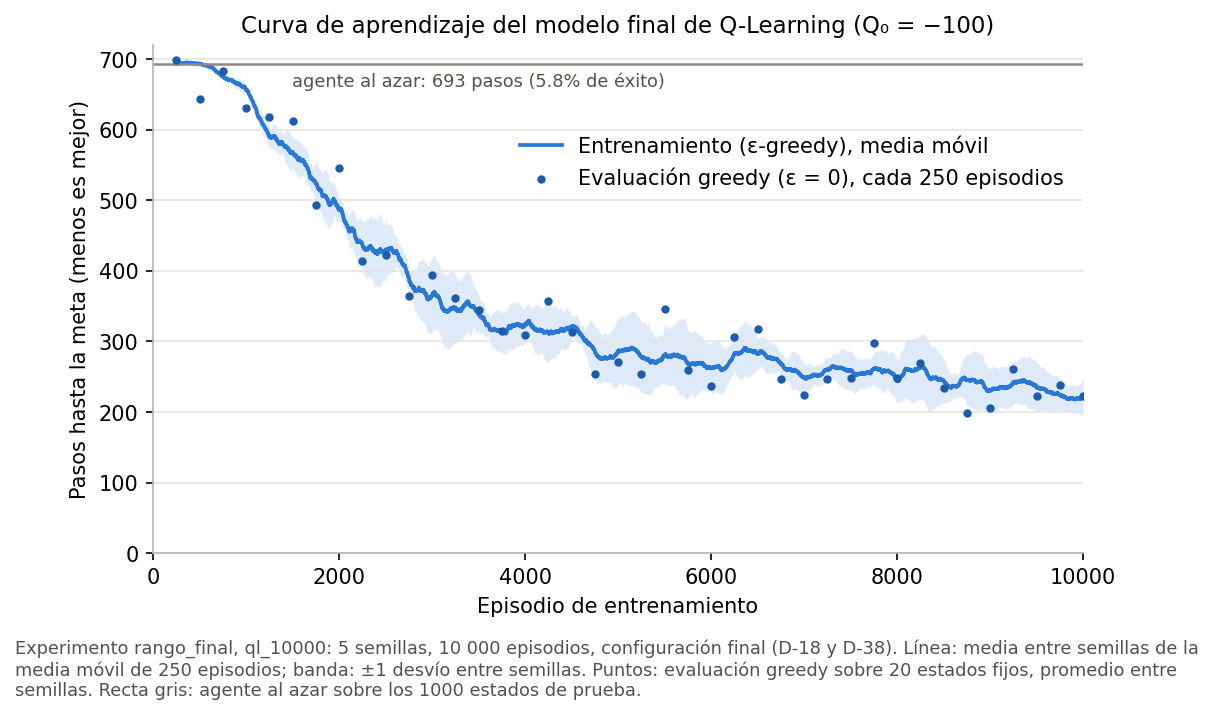

In [7]:
display(Image(filename="figures/A1_curva_modelo_final.png"))

### A2. Barridos de hiperparámetros con Q₀ = −100

Cada figura tiene las curvas de aprendizaje a la izquierda y el resultado greedy final (media ± desvío entre 5 semillas) a la derecha. La variante elegida está en negrita. Los barridos con Q₀ = 0 (`A2_cero_*.png`, de antes de la indicación del docente) están en `figures/` y van a los anexos del informe.

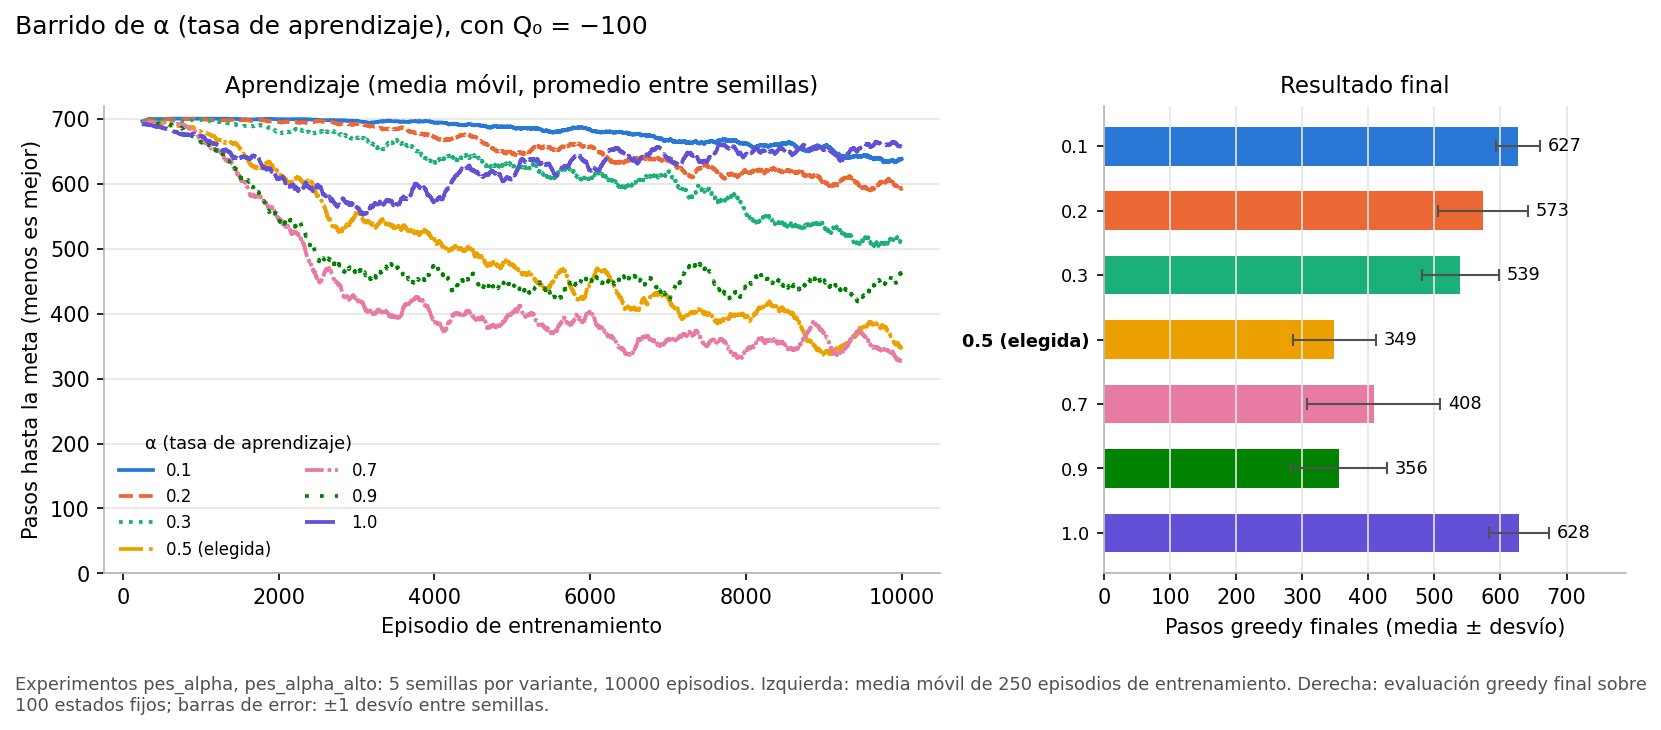

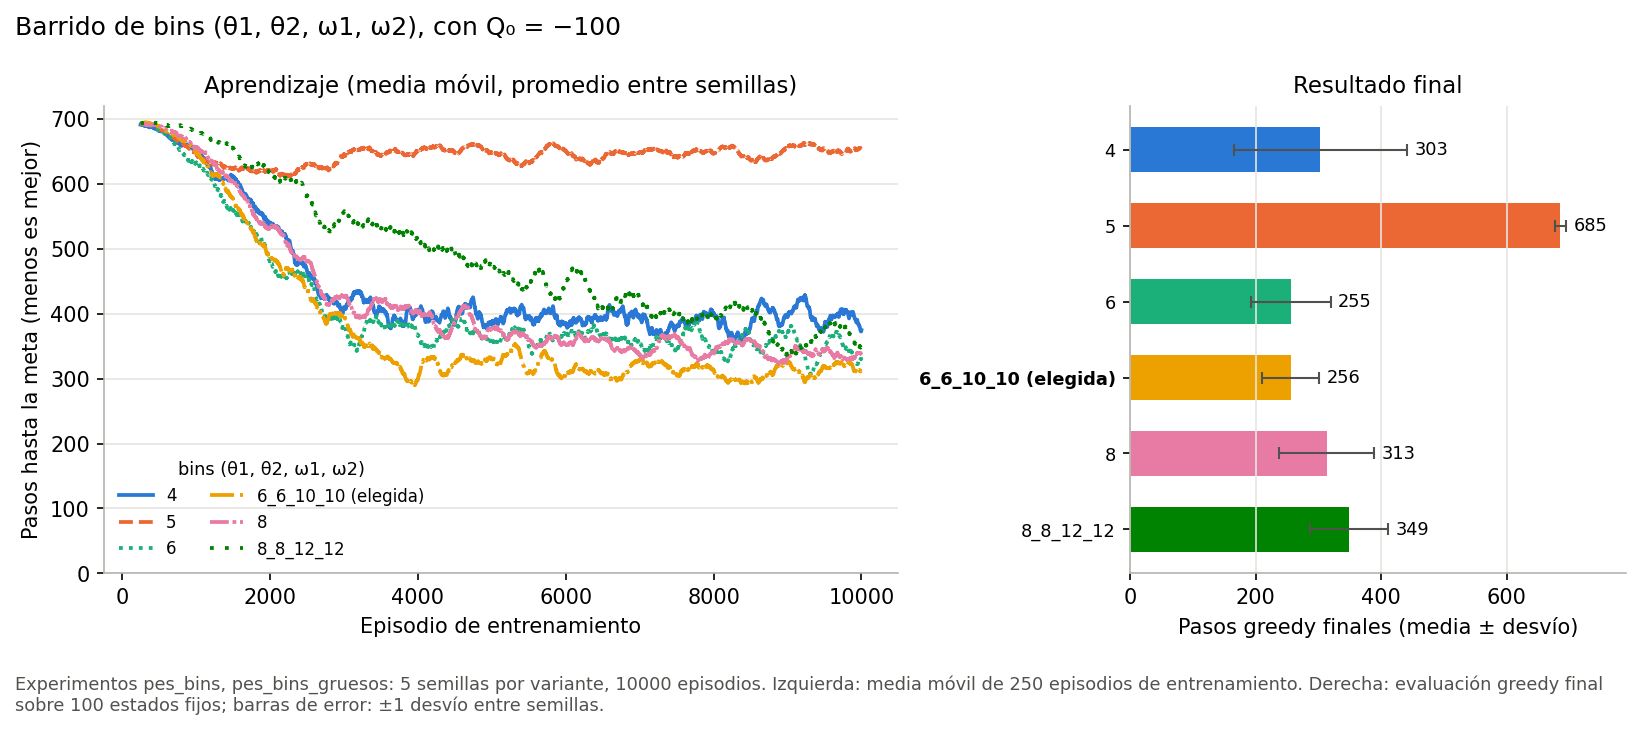

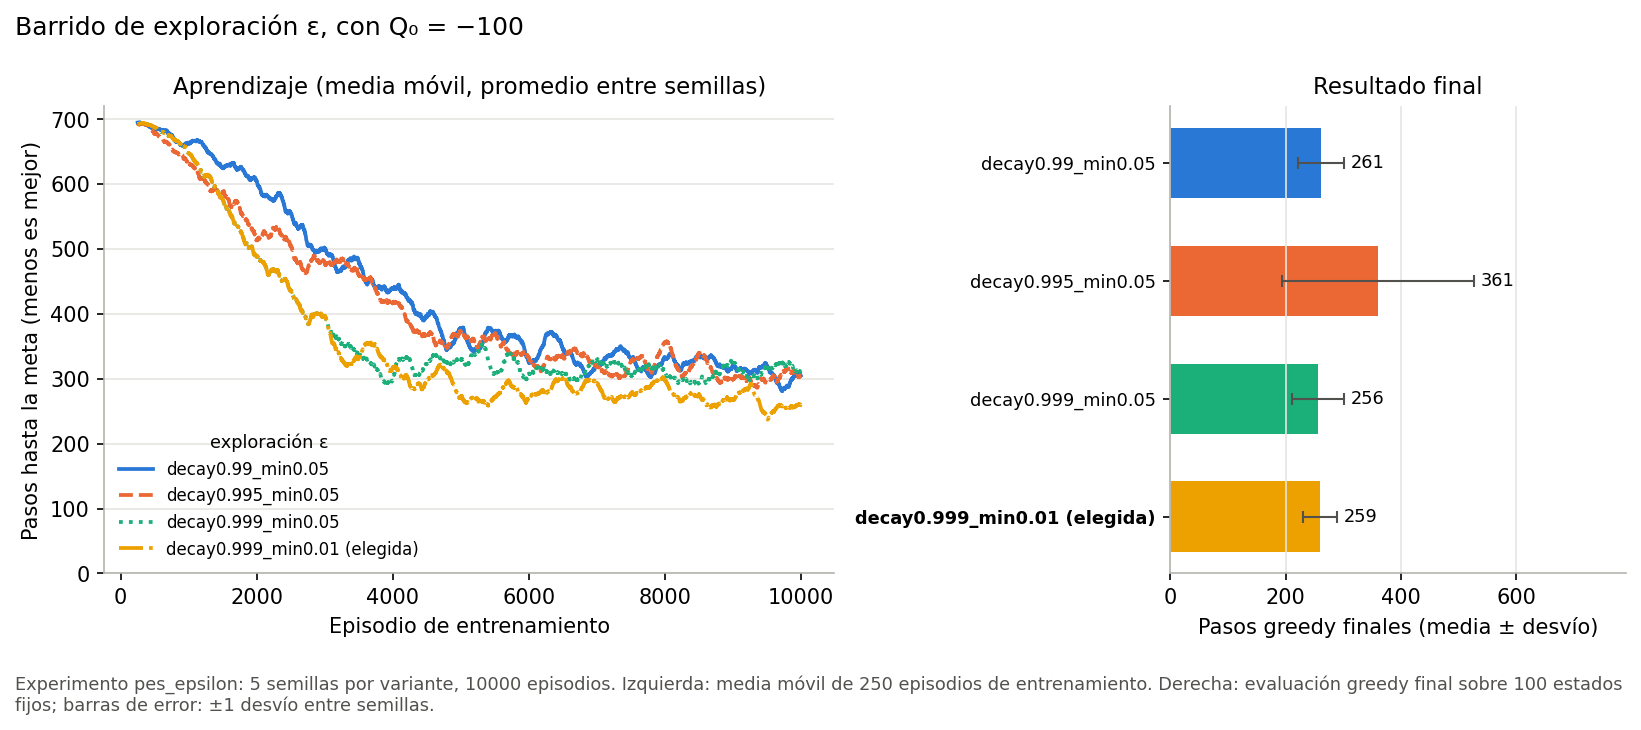

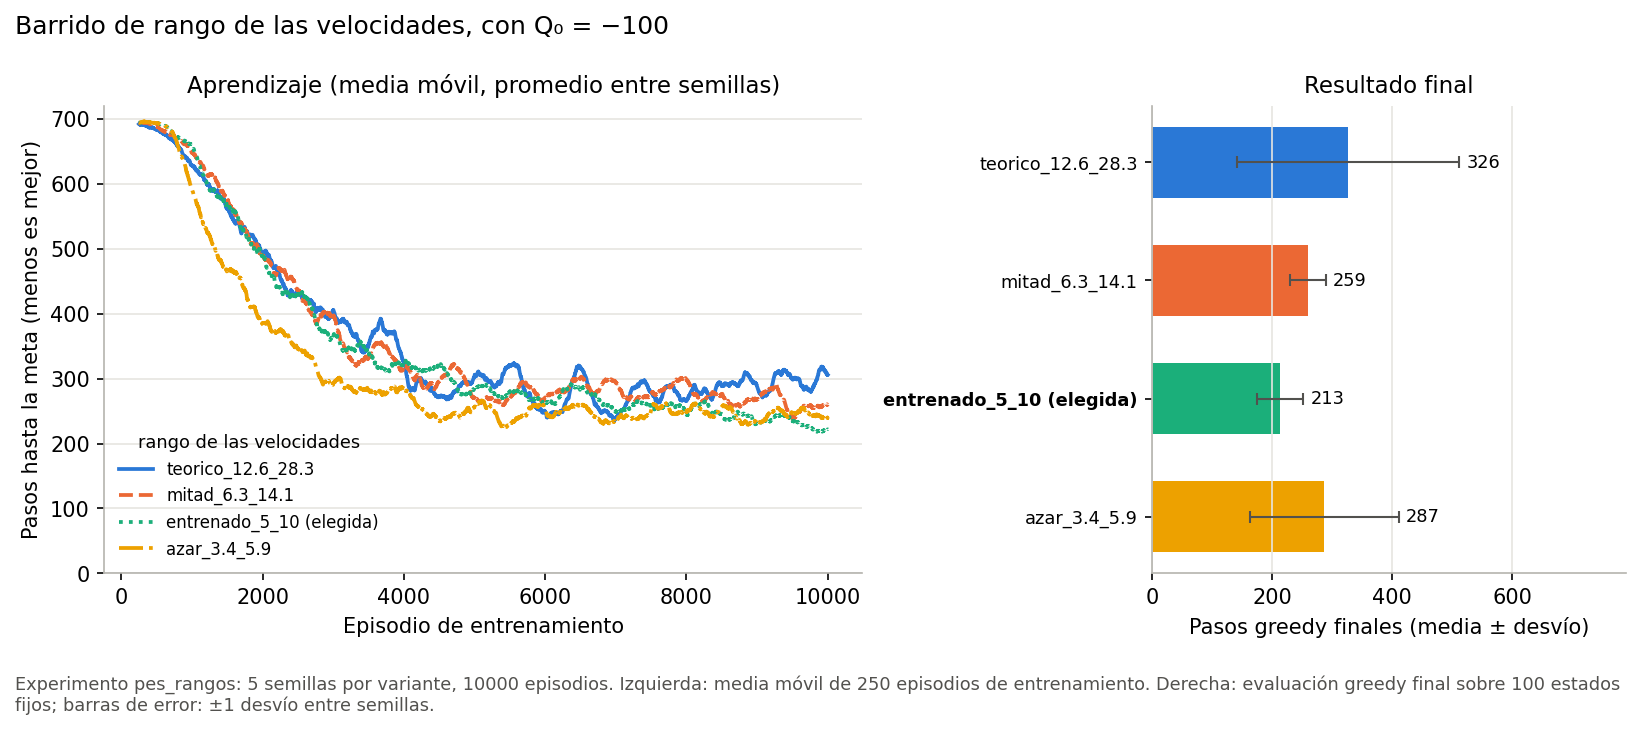

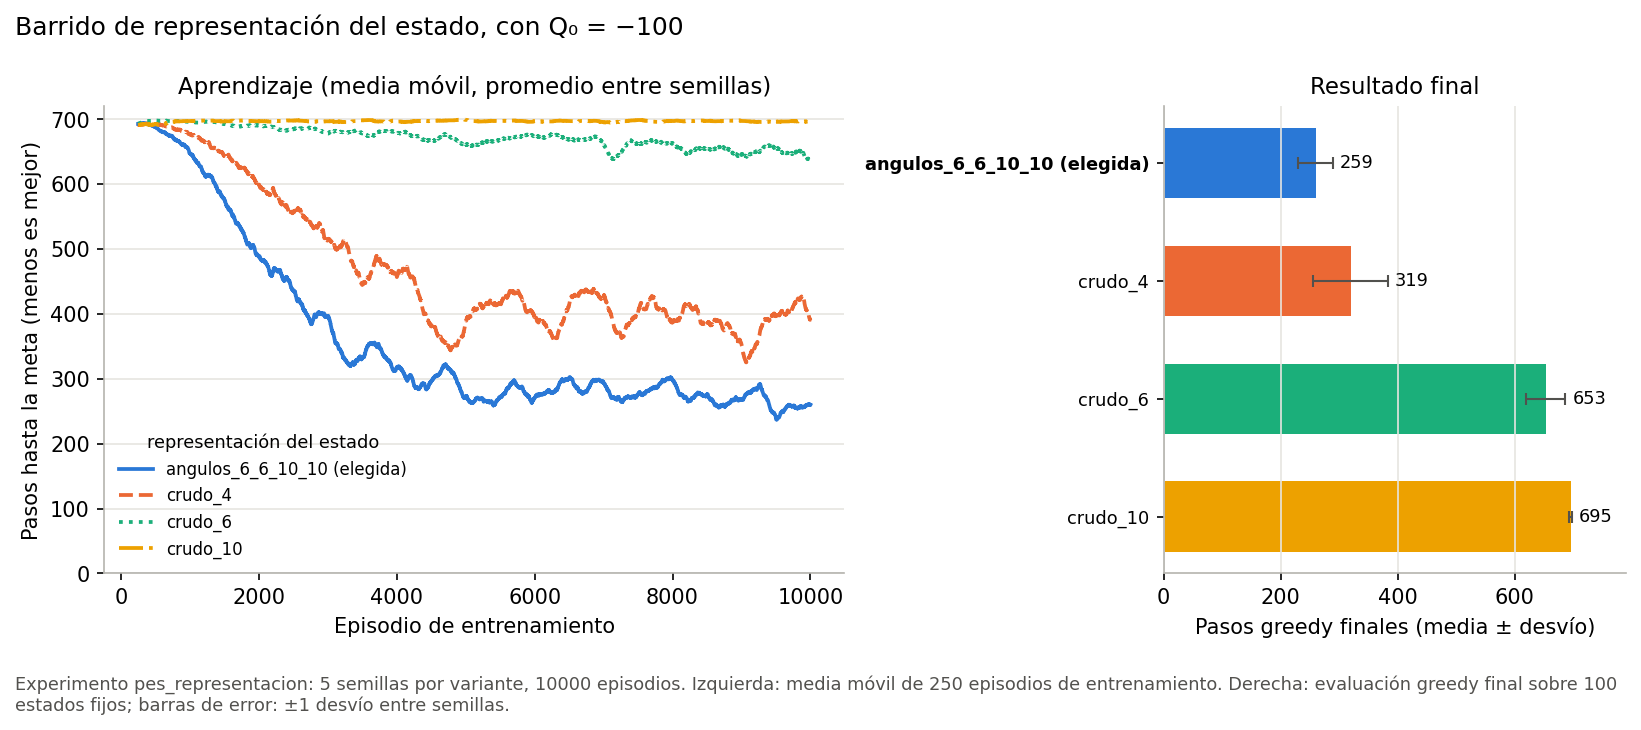

In [8]:
for name in ["A2_pes_alpha", "A2_pes_bins", "A2_pes_epsilon", "A2_pes_rangos", "A2_pes_representacion"]:
    display(Image(filename=f"figures/{name}.png"))

- **α (D-18):** con Q₀ = −100, una α baja no alcanza para propagar el valor de las llegadas: con 0.1 queda en 627 pasos. α = 0.5 llega a 349 pasos y 93 % de éxito. α = 1 colapsa (628 pasos), porque cada actualización se olvida de todo lo anterior y el *aliasing* de la discretización la desestabiliza.
- **Bins (D-18):** con inicialización pesimista conviene una tabla chica, con menos celdas por las que propagar el valor. Con 5 bins no aprende (685 pasos). Con una cantidad impar de bins, el bin del medio mezcla velocidades positivas y negativas, y en el punto más bajo no se distingue hacia dónde se mueve el péndulo.
- **ε (D-18):** el decay lento (0.999) con piso 0.01 es el más estable (259 ± 30).
- **Rango de las velocidades (D-36, D-38):** con Q₀ = −100 gana el rango que alcanza el agente entrenado (±5 / ±10): 213 pasos y 100 % de éxito, contra 259 de la mitad de los límites, que había ganado con Q₀ = 0. Con Q₀ = −100 conviene más resolución donde están la mayoría de las visitas.
- **Representación (D-36):** los ángulos ganan a cos/sin con el mismo tamaño de tabla (259 contra 319), y las tablas grandes de cos/sin no aprenden: 46 656 o 10⁶ celdas no se llegan a visitar.

### A3. Inicialización optimista (Q₀ = 0) contra pesimista (Q₀ = −100)

**a)** Con la misma configuración, Q₀ = −100 queda plana en 700. Es el punto fijo de la actualización: con Q(s′, ·) = −100, el objetivo vale −1 + 0.99 · (−100) = −100, igual al valor actual, así que la tabla solo cambia cuando el agente llega a la meta (D-17). **b)** Con los hiperparámetros ajustados para cada una, Q₀ = −100 sí aprende, pero más lento. Es el costo de cumplir la indicación del docente: en la prueba, 172 pasos contra 142.

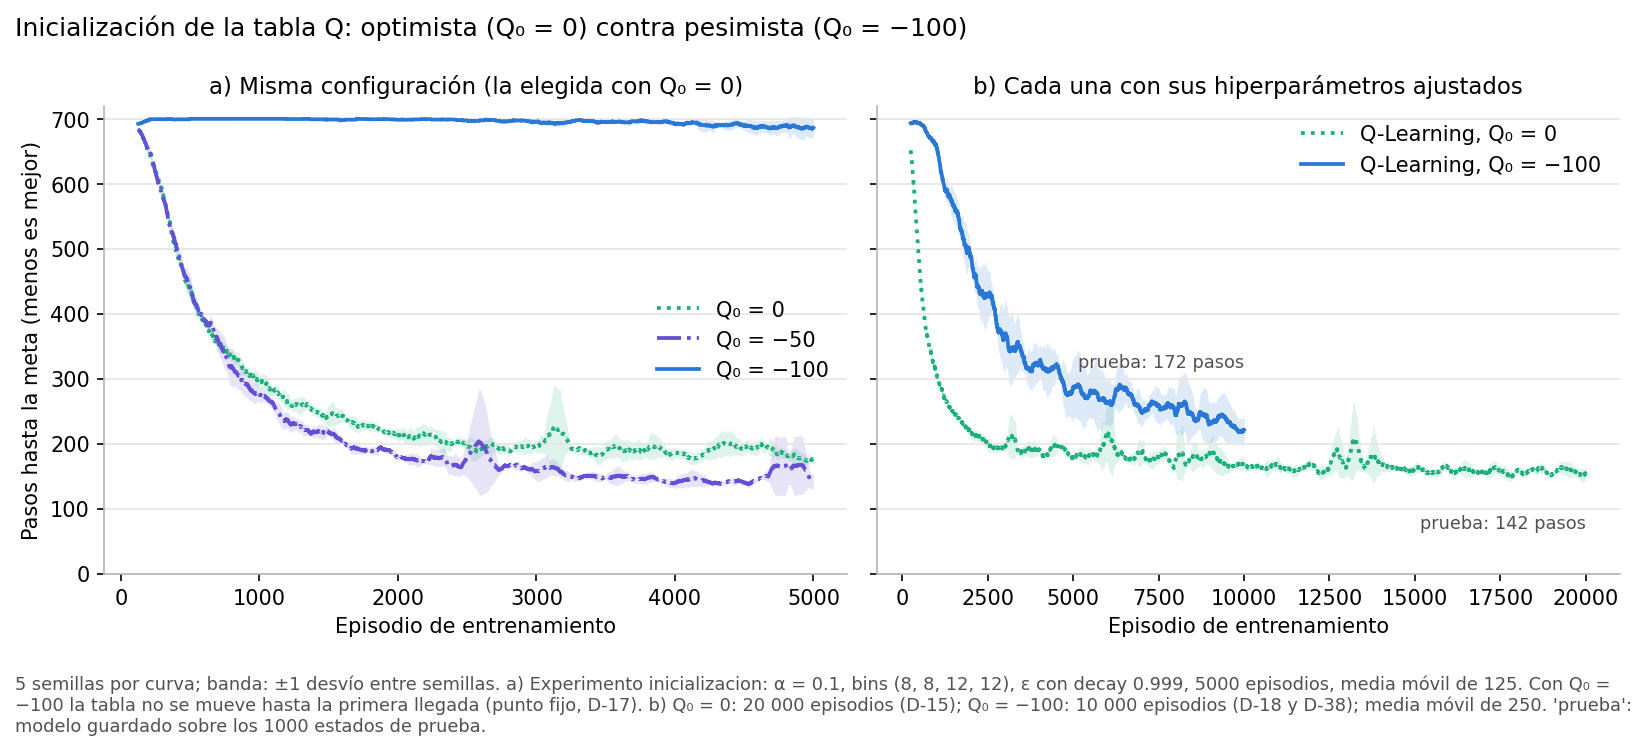

In [9]:
display(Image(filename="figures/A3_inicializacion.png"))

### A4. Distribución de pasos en los 1000 estados de prueba

Dyna-Q tiene la mediana más baja junto con Q-Learning con Q₀ = 0. Q-Learning con Q₀ = −100 tiene más dispersión. Los tres modelos fallan en muy pocos estados (llegan al corte de 700): 1, 1 y 4 de 1000. El agente al azar llega solo en el 5.8 % de los estados (D-35).

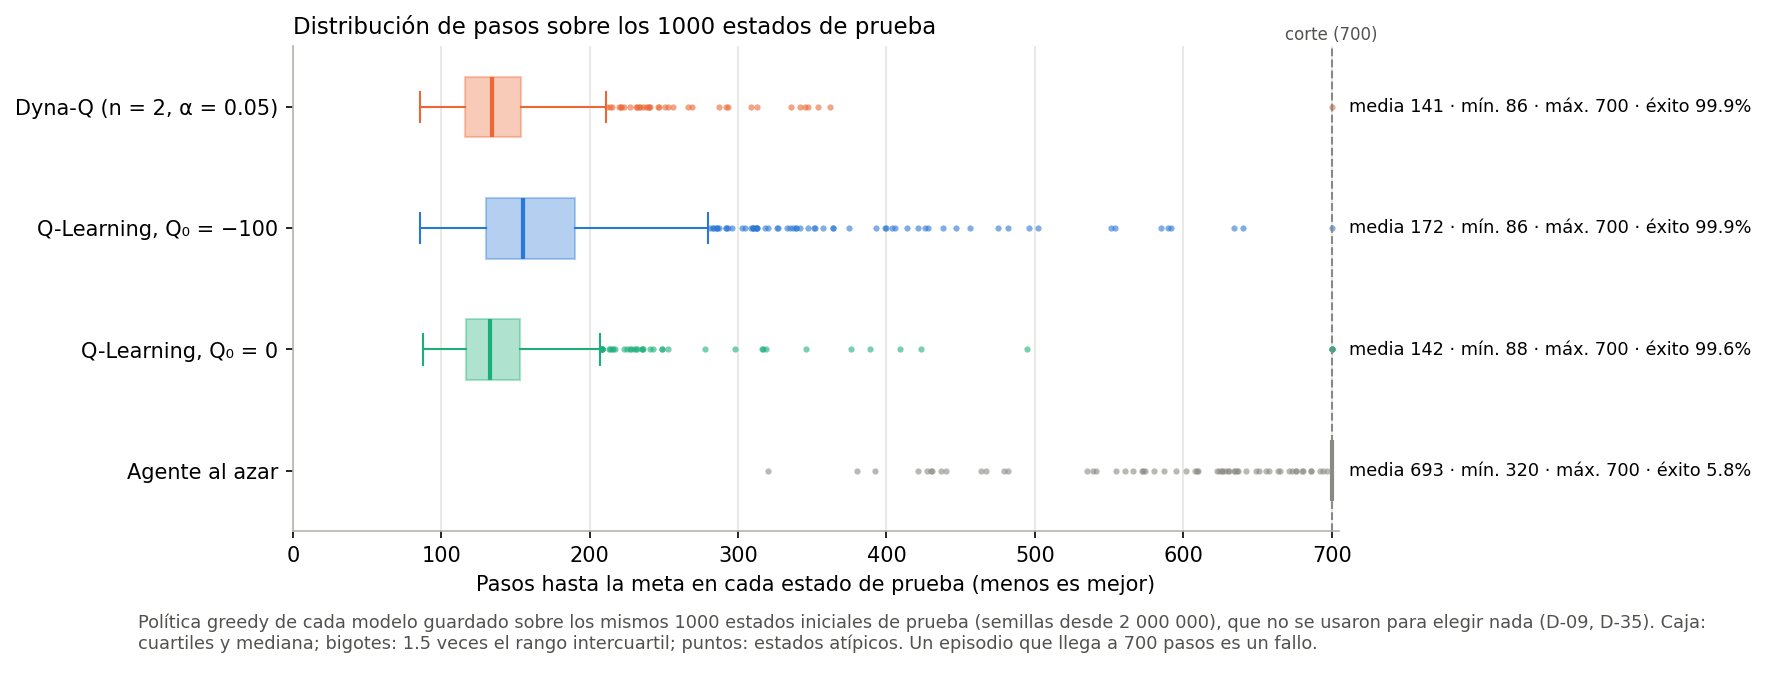

In [10]:
display(Image(filename="figures/A4_distribucion_prueba.png"))

### A5. Q-Learning contra Dyna-Q

Los dos algoritmos corrieron en el mismo lote, con la misma discretización y la misma exploración. **a)** Por episodios, Dyna-Q aprende mucho más rápido: a los 2000 episodios ya está cerca de 160 pasos. Es la eficiencia muestral del *planning*: cada paso real se reutiliza n = 2 veces más con el modelo. **b)** Por tiempo de reloj, Dyna-Q también gana, aunque hace 3 actualizaciones por paso: aprende antes, así que sus episodios se acortan antes (D-25, D-38).

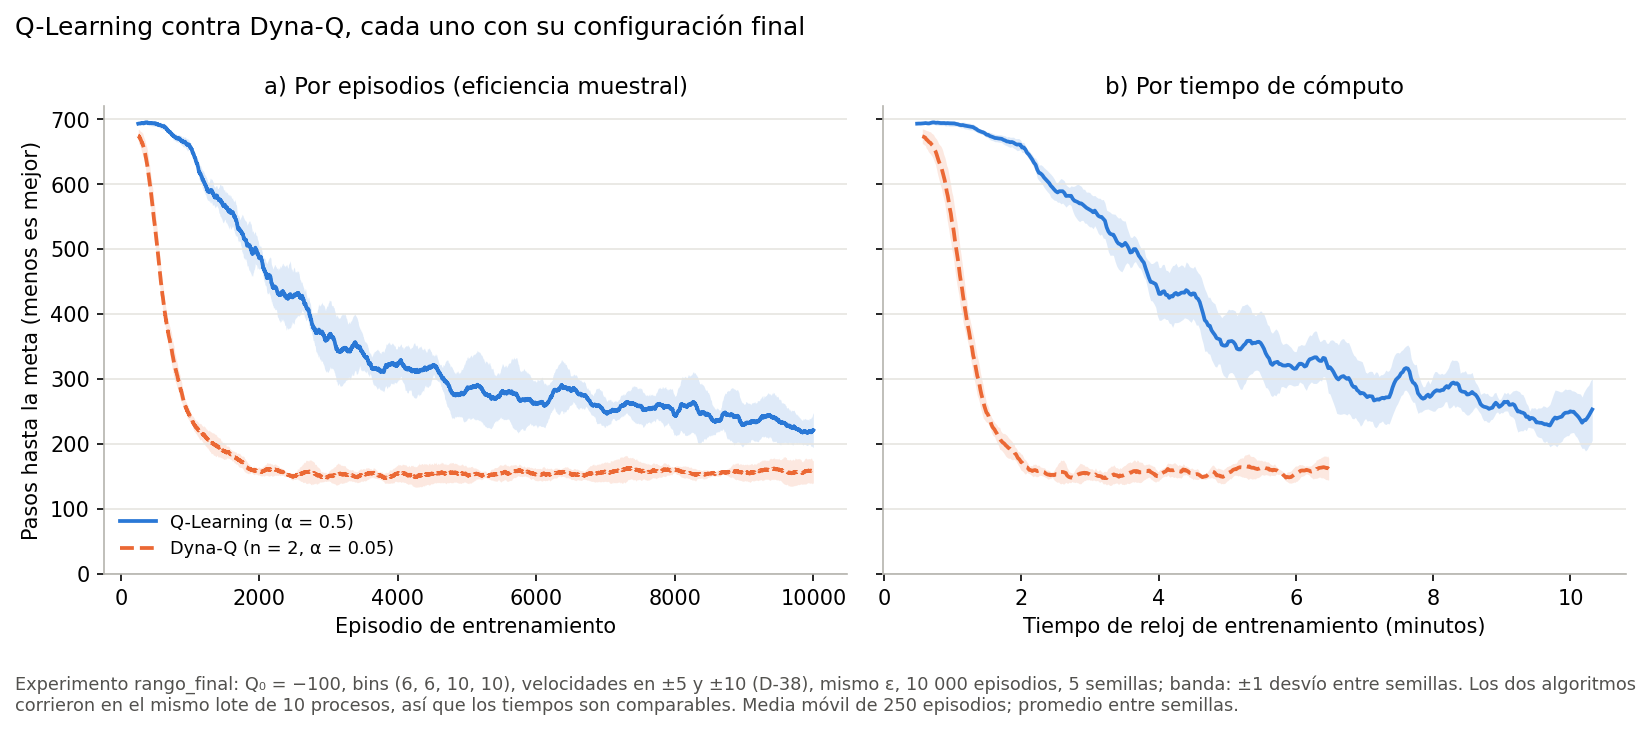

In [11]:
display(Image(filename="figures/A5_qlearning_vs_dynaq.png"))

### A5 (complemento). Cuánto *planning*: n con α = 0.5

Con la α de Q-Learning (0.5), más *planning* no ayuda, y con n ≥ 25 hay semillas que no aprenden. La causa es el *aliasing*: el modelo determinista de Dyna-Q guarda la última transición de cada (s, a), pero una celda agrupa muchos estados reales y lleva a celdas distintas. El modelo acierta solo el 28 % de las transiciones, y con n grande ese error se repite muchas veces (D-22, D-23). Por eso Dyna-Q usa n = 2 y α = 0.05: un poco de *planning* propaga el valor, y una α baja promedia el error del modelo (D-24).

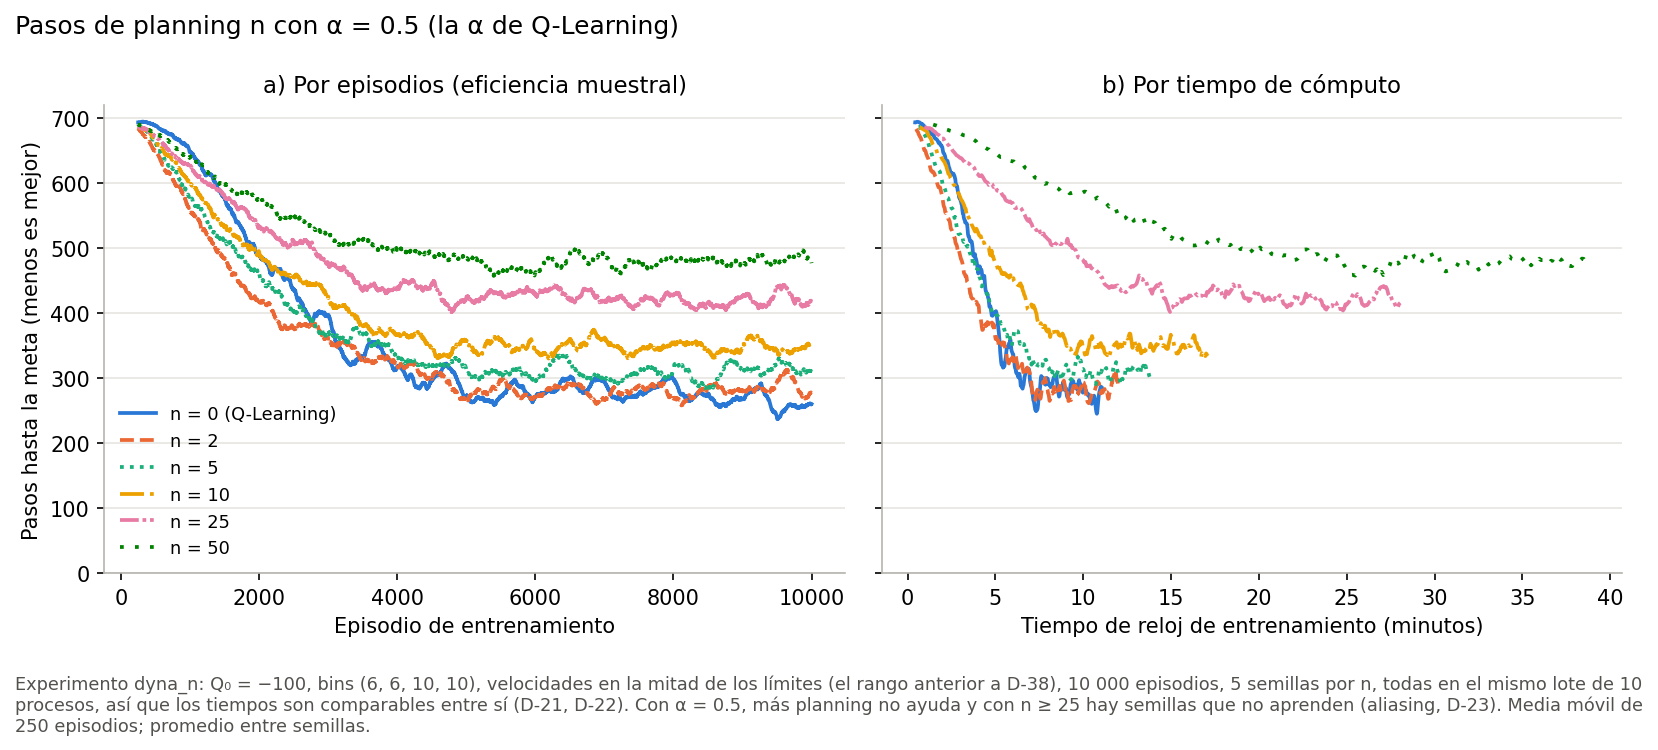

In [12]:
display(Image(filename="figures/A5_dyna_n.png"))

## 6. Cómo reproducir

Desde `Acrobot/`, con el entorno activado (o anteponiendo `poetry run`):

```bash
python train.py --save-model                     # Q-Learning, configuración final (unos 5 min)
python train.py --algorithm dynaq --save-model   # Dyna-Q, configuración final (unos 3 min)
python evaluate_model.py models/<run_id>.pkl     # 1000 estados de prueba (--render 3 para verlo)
python sweep.py <experimento>                    # un barrido: variantes x 5 semillas, en paralelo
python plots.py                                  # todas las figuras
```

El código es determinista con la misma semilla: volver a entrenar reproduce exactamente los mismos números (D-16).

## Anexo: simulación al azar (celda de la cátedra)

Un episodio con acciones al azar, como en el notebook original. Solo se muestra con `RENDER = True`.

In [13]:
from random import randint

if RENDER:
    env = gym.make("Acrobot-v1", render_mode="human", max_episode_steps=700)
    obs, _ = env.reset()
    done = False
    while not done:
        obs, reward, terminated, truncated, _ = env.step(randint(0, 2))
        done = terminated or truncated
    env.close()